# Where magnitude correlation and sign accuracy peak

This notebook reads the five saved latent pairs in `results/geometric_registration/latent_undo_n5`. It does not generate images or run diffusion.

Each inverted latent `z_hat` came from an image that had been shifted or rotated by a known amount. Here that latent is corrected by many hypothesized amounts, not only the true one. Two scores are computed at every hypothesis, both as a mean over the five images. The star sits at the true image perturbation.

The first score is `pearsonr(|z|, |corrected latent|)`, the same absolute-value correlation as the registration run. The second is sign-bit accuracy: a coordinate is correct when `z` and the corrected latent are both `>= 0` or both `< 0`. That is the Gaussian Shading sign rule. Exact zero counts as nonnegative. Accuracy is the fraction of the 16,384 coordinates that agree, so 0.5 is what independent signs would score.

A hypothesized shift of `n` pixels moves the latent by `n/8` pixels in the opposite direction, with linear interpolation. A hypothesized rotation of `n` degrees rotates each latent channel by `n` degrees in the opposite direction, with a cubic spline. Vacated sites are filled with 0. Linear interpolation is used for shifts because nearest-neighbor latent shifts are constant across several image pixels, so a finer pixel axis would otherwise repeat the same score. Candidate 0 leaves the inverted latent unchanged.


## 1. Load the five samples


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy import ndimage
from scipy.stats import pearsonr

RUN_DIR = Path("results/geometric_registration/latent_undo_n5")
LATENT_DIR = RUN_DIR / "latents"
if not LATENT_DIR.is_dir():
    raise SystemExit(f"Missing {LATENT_DIR}. Copy the HiPerGator latent_undo_n5 directory here first.")

meta = json.loads((RUN_DIR / "metadata.json").read_text(encoding="utf-8"))
VAE_SCALE_FACTOR = int(meta["vae_scale_factor"])
CONDITIONS = [(row["transformation_type"], float(row["magnitude"])) for row in meta["conditions"]]
FAMILIES = ["horizontal_translation", "vertical_translation", "rotation"]
FAMILY_TITLES = {
    "horizontal_translation": "hypothesized horizontal undo (pixels)",
    "vertical_translation": "hypothesized vertical undo (pixels)",
    "rotation": "hypothesized rotation undo (degrees)",
}
TRUE_MAGNITUDES = [0.0, 1.0, 2.0, 5.0, 10.0]
CANDIDATES = np.round(np.arange(0.0, 12.0 + 1e-9, 0.5), 1)
for magnitude in TRUE_MAGNITUDES:
    if magnitude not in set(CANDIDATES):
        raise SystemExit(f"true magnitude {magnitude} is not on the candidate grid")

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

blobs = []
for sample_id in range(int(meta["num_samples"])):
    path = LATENT_DIR / f"sample_{sample_id:03d}.pt"
    if not path.is_file():
        raise SystemExit(f"missing {path}")
    blobs.append(torch.load(path, map_location="cpu", weights_only=True))
print(f"loaded {len(blobs)} samples, {len(CANDIDATES)} candidate corrections per curve")
print(f"true perturbations: {TRUE_MAGNITUDES}")


loaded 5 samples, 25 candidate corrections per curve
true perturbations: [0.0, 1.0, 2.0, 5.0, 10.0]


## 2. Score every hypothesized correction

For a horizontal or vertical condition, the image content was moved right or down. The correction moves the latent left or up. For a rotation, the image was turned counterclockwise and the correction turns the latent clockwise. The baseline latent is included as a true perturbation of 0, and the same family of corrections is applied to it. Each correction is scored once for magnitude correlation and once for sign-bit accuracy.


In [2]:
def latent_key(kind: str, magnitude: float) -> str:
    return f"z_hat__{kind}__{magnitude:.1f}"


def correct_latent(latent: np.ndarray, kind: str, candidate: float) -> np.ndarray:
    spatial = np.asarray(latent, dtype=np.float32)
    if spatial.ndim == 4:
        spatial = spatial[0]
    if candidate == 0:
        return spatial.copy()
    if kind == "horizontal_translation":
        shift = (0.0, -candidate / VAE_SCALE_FACTOR)
        order = 1
        moved = [ndimage.shift(channel, shift=shift, order=order, mode="constant", cval=0.0) for channel in spatial]
    elif kind == "vertical_translation":
        shift = (-candidate / VAE_SCALE_FACTOR, 0.0)
        moved = [ndimage.shift(channel, shift=shift, order=1, mode="constant", cval=0.0) for channel in spatial]
    elif kind == "rotation":
        moved = [
            ndimage.rotate(channel, angle=-candidate, reshape=False, order=3, mode="constant", cval=0.0, prefilter=True)
            for channel in spatial
        ]
    else:
        raise ValueError(kind)
    return np.stack(moved, axis=0).astype(np.float32)


def magnitude_correlation(z: np.ndarray, other: np.ndarray) -> float:
    left = np.abs(np.asarray(z, dtype=np.float64)).ravel()
    right = np.abs(np.asarray(other, dtype=np.float64)).ravel()
    result = pearsonr(left, right)
    return float(result.statistic)


def sign_bit_accuracy(z: np.ndarray, other: np.ndarray) -> float:
    # z >= 0 is the nonnegative sign, so exact zero agrees with exact zero.
    left = (np.asarray(z) >= 0).ravel()
    right = (np.asarray(other) >= 0).ravel()
    if left.size != right.size:
        raise ValueError(f"sign comparison has {left.size} and {right.size} coordinates")
    return float(np.mean(left == right))


rows = []
for sample_id, blob in enumerate(blobs):
    z = blob["z"].numpy()
    for kind in FAMILIES:
        for true_magnitude in TRUE_MAGNITUDES:
            source_kind = "baseline" if true_magnitude == 0 else kind
            z_hat = blob[latent_key(source_kind, true_magnitude)].numpy()
            for candidate in CANDIDATES:
                corrected = correct_latent(z_hat, kind, float(candidate))
                rows.append({
                    "sample_id": sample_id,
                    "transformation_type": kind,
                    "true_magnitude": true_magnitude,
                    "candidate": float(candidate),
                    "correlation": magnitude_correlation(z, corrected),
                    "bit_accuracy": sign_bit_accuracy(z, corrected),
                })
    print(f"scored sample {sample_id + 1}/{len(blobs)}", flush=True)

scores = pd.DataFrame(rows)
if not np.isfinite(scores.correlation).all() or not np.isfinite(scores.bit_accuracy).all():
    raise SystemExit("a score is non-finite")
if scores.bit_accuracy.min() < 0 or scores.bit_accuracy.max() > 1:
    raise SystemExit("bit accuracy left [0, 1]")
print(f"rows {len(scores)}")


scored sample 1/5


scored sample 2/5


scored sample 3/5


scored sample 4/5


scored sample 5/5


rows 1875


## 3. Both scores against the hypothesized perturbation

Each line is one true image perturbation. The star marks that true amount on its own line. The first figure is magnitude correlation. The second is sign-bit accuracy, with a dashed line at 0.5, the accuracy of signs that do not depend on `z`. A peak on the star means that score is highest when the latent is corrected by the perturbation that was actually applied.


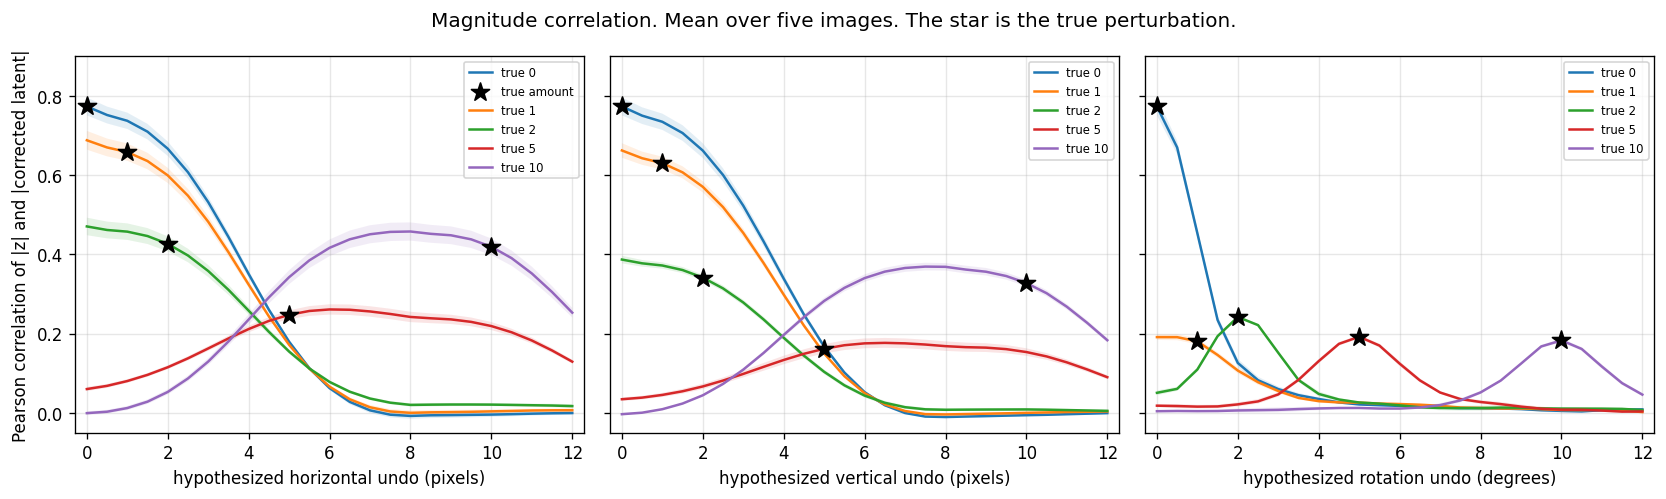

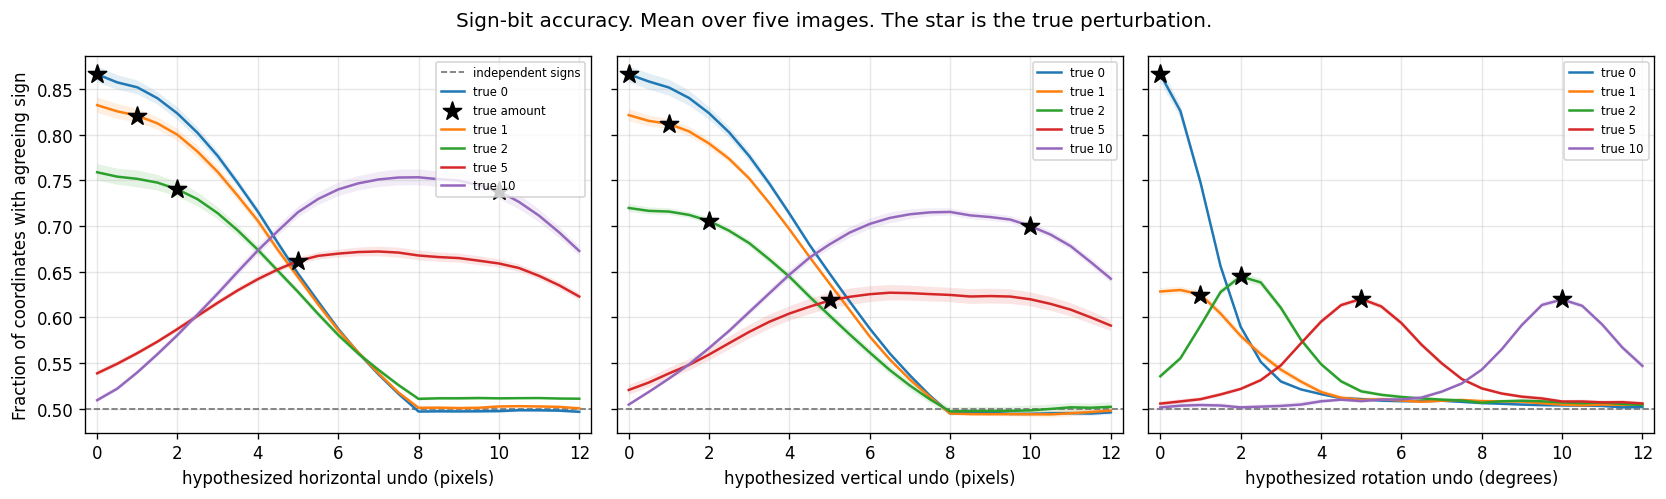

In [3]:
def summarize(column: str) -> pd.DataFrame:
    out = (
        scores.groupby(["transformation_type", "true_magnitude", "candidate"])[column]
        .agg(mean="mean", std="std", count="count")
        .reset_index()
    )
    out["sem"] = out["std"] / np.sqrt(out["count"])
    return out


def draw_sweep(summary: pd.DataFrame, ylabel: str, title: str, ylim: tuple[float, float], chance: float | None = None) -> None:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
    marked = False
    for ax, kind in zip(axes, FAMILIES):
        block = summary.loc[summary.transformation_type == kind]
        if chance is not None:
            ax.axhline(chance, color="0.45", ls="--", lw=1, label="independent signs" if ax is axes[0] else None)
        for true_magnitude in TRUE_MAGNITUDES:
            curve = block.loc[np.isclose(block.true_magnitude, true_magnitude)].sort_values("candidate")
            ax.plot(curve.candidate, curve["mean"], label=f"true {true_magnitude:g}")
            ax.fill_between(
                curve.candidate,
                curve["mean"] - curve["sem"],
                curve["mean"] + curve["sem"],
                alpha=0.12,
            )
            at_true = curve.loc[np.isclose(curve.candidate, true_magnitude)].iloc[0]
            ax.scatter(
                [true_magnitude],
                [at_true["mean"]],
                marker="*",
                s=130,
                color="black",
                zorder=5,
                label="true amount" if not marked else None,
            )
            marked = True
        ax.set(xlabel=FAMILY_TITLES[kind], xlim=(-0.3, 12.3), ylim=ylim)
        ax.legend(fontsize=7, loc="best")
    axes[0].set_ylabel(ylabel)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


corr_summary = summarize("correlation")
bit_summary = summarize("bit_accuracy")
draw_sweep(
    corr_summary,
    "Pearson correlation of |z| and |corrected latent|",
    "Magnitude correlation. Mean over five images. The star is the true perturbation.",
    (-0.05, 0.9),
)
bit_lo = min(0.48, float(bit_summary["mean"].min()) - 0.02)
bit_hi = float(bit_summary["mean"].max()) + 0.02
draw_sweep(
    bit_summary,
    "Fraction of coordinates with agreeing sign",
    "Sign-bit accuracy. Mean over five images. The star is the true perturbation.",
    (bit_lo, bit_hi),
    chance=0.5,
)



## How the two scores move together

Each path is one true perturbation, traced as the hypothesized undo runs from 0 to 12. Magnitude correlation is on the horizontal axis and sign-bit accuracy is on the vertical axis. The star is the true undo. Paths that travel up and to the right are corrections that raise both scores. A path that moves up while moving left, or the reverse, is a correction that helps one score and hurts the other.


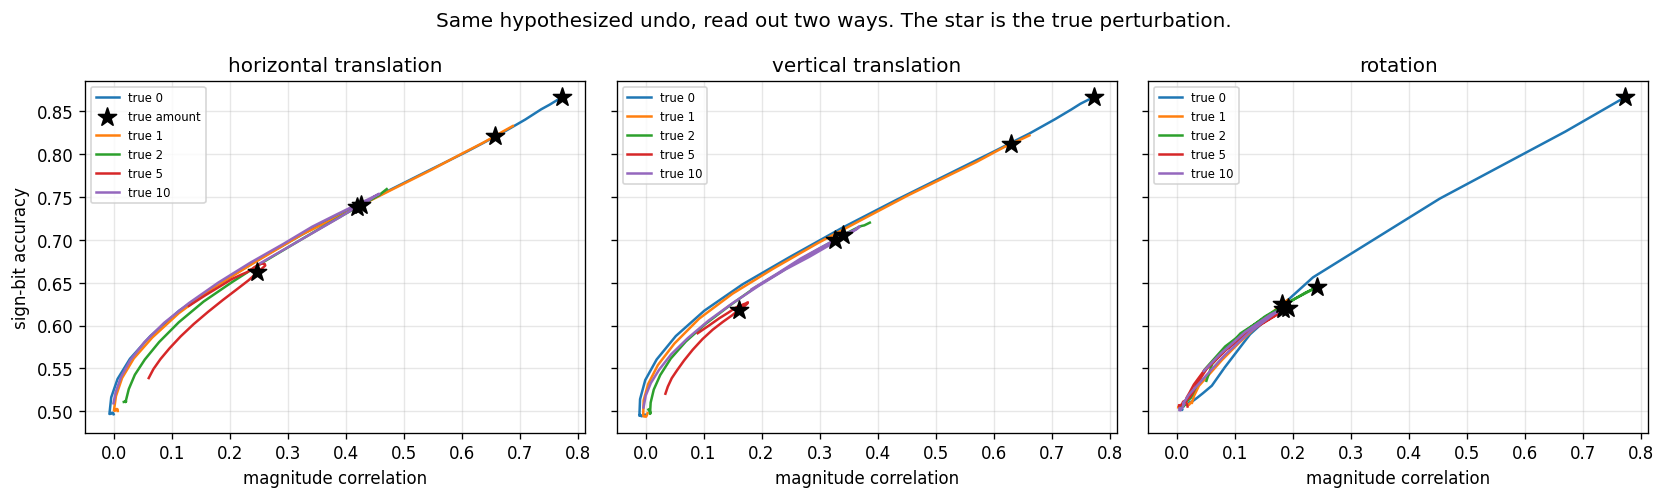

horizontal_translation true 0: correlation between the two mean curves is 0.986
horizontal_translation true 1: correlation between the two mean curves is 0.984
horizontal_translation true 2: correlation between the two mean curves is 0.987
horizontal_translation true 5: correlation between the two mean curves is 0.972
horizontal_translation true 10: correlation between the two mean curves is 0.987
vertical_translation true 0: correlation between the two mean curves is 0.983
vertical_translation true 1: correlation between the two mean curves is 0.981
vertical_translation true 2: correlation between the two mean curves is 0.981
vertical_translation true 5: correlation between the two mean curves is 0.978
vertical_translation true 10: correlation between the two mean curves is 0.988
rotation true 0: correlation between the two mean curves is 0.994
rotation true 1: correlation between the two mean curves is 0.996
rotation true 2: correlation between the two mean curves is 0.985
rotation t

In [4]:
paired = corr_summary.merge(
    bit_summary,
    on=["transformation_type", "true_magnitude", "candidate"],
    suffixes=("_corr", "_bit"),
)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True, sharey=True)
marked = False
for ax, kind in zip(axes, FAMILIES):
    block = paired.loc[paired.transformation_type == kind]
    for true_magnitude in TRUE_MAGNITUDES:
        curve = block.loc[np.isclose(block.true_magnitude, true_magnitude)].sort_values("candidate")
        ax.plot(curve.mean_corr, curve.mean_bit, label=f"true {true_magnitude:g}")
        at_true = curve.loc[np.isclose(curve.candidate, true_magnitude)].iloc[0]
        ax.scatter(
            [at_true.mean_corr],
            [at_true.mean_bit],
            marker="*",
            s=130,
            color="black",
            zorder=5,
            label="true amount" if not marked else None,
        )
        marked = True
    ax.set(xlabel="magnitude correlation", title=kind.replace("_", " "))
    ax.legend(fontsize=7, loc="best")
axes[0].set_ylabel("sign-bit accuracy")
fig.suptitle("Same hypothesized undo, read out two ways. The star is the true perturbation.")
fig.tight_layout()
plt.show()

for kind in FAMILIES:
    for true_magnitude in TRUE_MAGNITUDES:
        curve = paired.loc[
            (paired.transformation_type == kind) & np.isclose(paired.true_magnitude, true_magnitude)
        ]
        relation = pearsonr(curve.mean_corr, curve.mean_bit).statistic
        print(f"{kind} true {true_magnitude:g}: correlation between the two mean curves is {relation:.3f}")


## 4. Does each curve peak at the true amount?

The peak is the candidate with the highest mean score. If several candidates tie, the one closest to the true perturbation is kept. The sample count is how many of the five images have their own peak at that same true amount. Magnitude correlation and sign-bit accuracy are reported separately, including whether those two peaks land on the same candidate.


In [5]:
def peak_of(candidates: np.ndarray, values: np.ndarray, true_magnitude: float) -> float:
    best = np.max(values)
    tied = candidates[np.isclose(values, best)]
    return float(tied[np.argmin(np.abs(tied - true_magnitude))])


def peak_table(summary: pd.DataFrame, column: str) -> pd.DataFrame:
    sample_rows = []
    for (sample_id, kind, true_magnitude), group in scores.groupby(
        ["sample_id", "transformation_type", "true_magnitude"]
    ):
        sample_rows.append({
            "sample_id": sample_id,
            "transformation_type": kind,
            "true_magnitude": float(true_magnitude),
            "sample_peak": peak_of(group.candidate.to_numpy(), group[column].to_numpy(), float(true_magnitude)),
        })
    sample_peaks = pd.DataFrame(sample_rows)
    lines = []
    for kind in FAMILIES:
        for true_magnitude in TRUE_MAGNITUDES:
            curve = summary.loc[
                (summary.transformation_type == kind) & np.isclose(summary.true_magnitude, true_magnitude)
            ]
            peak = peak_of(curve.candidate.to_numpy(), curve["mean"].to_numpy(), true_magnitude)
            at_true = float(curve.loc[np.isclose(curve.candidate, true_magnitude), "mean"].iloc[0])
            at_zero = float(curve.loc[np.isclose(curve.candidate, 0.0), "mean"].iloc[0])
            sample_peak = sample_peaks.loc[
                (sample_peaks.transformation_type == kind) & np.isclose(sample_peaks.true_magnitude, true_magnitude),
                "sample_peak",
            ]
            hits = int(np.isclose(sample_peak.to_numpy(), true_magnitude).sum())
            lines.append({
                "score": column,
                "transformation_type": kind,
                "true_magnitude": true_magnitude,
                "peak_candidate": peak,
                "score_at_peak": float(curve["mean"].max()),
                "score_at_true": at_true,
                "score_at_0": at_zero,
                "samples_peaking_at_true": hits,
            })
    return pd.DataFrame(lines)


peak_comparison = peak_table(corr_summary, "correlation").merge(
    peak_table(bit_summary, "bit_accuracy"),
    on=["transformation_type", "true_magnitude"],
    suffixes=("_corr", "_bit"),
)
for _, rec in peak_comparison.iterrows():
    same = "same candidate" if np.isclose(rec.peak_candidate_corr, rec.peak_candidate_bit) else "different candidates"
    print(
        f"{rec.transformation_type} true {rec.true_magnitude:g}: "
        f"correlation peaks at {rec.peak_candidate_corr:g} "
        f"({rec.samples_peaking_at_true_corr}/5 images at the true amount); "
        f"sign accuracy peaks at {rec.peak_candidate_bit:g} "
        f"({rec.samples_peaking_at_true_bit}/5 images at the true amount); "
        f"{same}"
    )
peak_comparison.round(3)


horizontal_translation true 0: correlation peaks at 0 (5/5 images at the true amount); sign accuracy peaks at 0 (5/5 images at the true amount); same candidate
horizontal_translation true 1: correlation peaks at 0 (0/5 images at the true amount); sign accuracy peaks at 0 (0/5 images at the true amount); same candidate
horizontal_translation true 2: correlation peaks at 0 (0/5 images at the true amount); sign accuracy peaks at 0 (0/5 images at the true amount); same candidate
horizontal_translation true 5: correlation peaks at 6 (0/5 images at the true amount); sign accuracy peaks at 7 (0/5 images at the true amount); different candidates
horizontal_translation true 10: correlation peaks at 8 (0/5 images at the true amount); sign accuracy peaks at 8 (0/5 images at the true amount); same candidate
vertical_translation true 0: correlation peaks at 0 (5/5 images at the true amount); sign accuracy peaks at 0 (5/5 images at the true amount); same candidate
vertical_translation true 1: correl

,score_corr,transformation_type,true_magnitude,peak_candidate_corr,score_at_peak_corr,score_at_true_corr,score_at_0_corr,samples_peaking_at_true_corr,score_bit,peak_candidate_bit,score_at_peak_bit,score_at_true_bit,score_at_0_bit,samples_peaking_at_true_bit
0,correlation,horizontal_translation,0.0,0.0,0.773,0.773,0.773,5,bit_accuracy,0.0,0.866,0.866,0.866,5
1,correlation,horizontal_translation,1.0,0.0,0.687,0.658,0.687,0,bit_accuracy,0.0,0.832,0.821,0.832,0
2,correlation,horizontal_translation,2.0,0.0,0.470,0.426,0.470,0,bit_accuracy,0.0,0.759,0.740,0.759,0
3,correlation,horizontal_translation,5.0,6.0,0.261,0.247,0.060,0,bit_accuracy,7.0,0.672,0.662,0.539,0
4,correlation,horizontal_translation,10.0,8.0,0.457,0.419,-0.001,0,bit_accuracy,8.0,0.753,0.738,0.509,0
5,correlation,vertical_translation,0.0,0.0,0.773,0.773,0.773,5,bit_accuracy,0.0,0.866,0.866,0.866,5
6,correlation,vertical_translation,1.0,0.0,0.662,0.630,0.662,0,bit_accuracy,0.0,0.822,0.812,0.822,0
7,correlation,vertical_translation,2.0,0.0,0.387,0.341,0.387,0,bit_accuracy,0.0,0.720,0.706,0.720,0
8,correlation,vertical_translation,5.0,6.5,0.176,0.162,0.034,0,bit_accuracy,6.5,0.627,0.619,0.521,0
9,correlation,vertical_translation,10.0,7.5,0.369,0.327,-0.003,0,bit_accuracy,8.0,0.715,0.700,0.505,0
